## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Becca Hobson

**Date:** 10/13/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


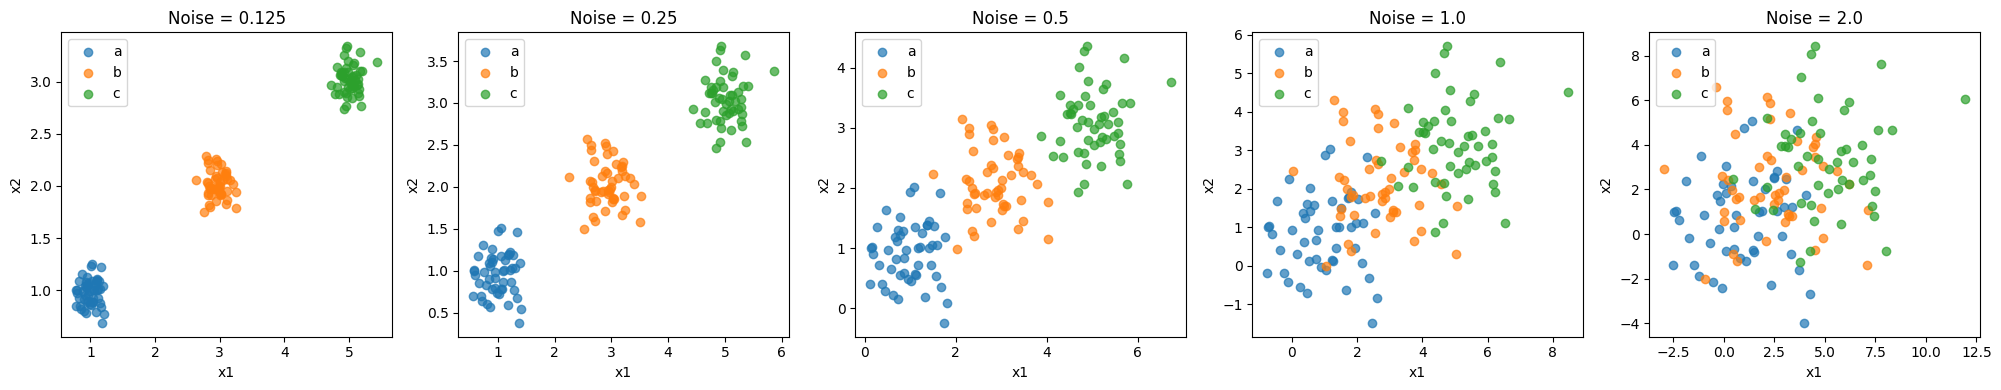

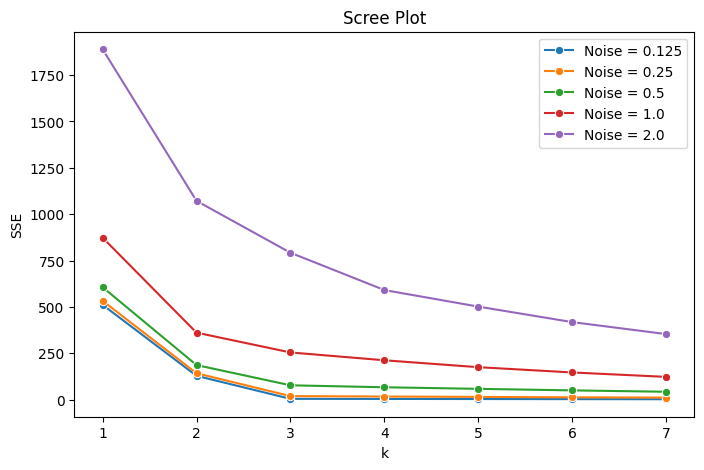

2.0 [1889.2, 1071.81, 792.27, 591.18, 501.88, 418.35, 353.84]


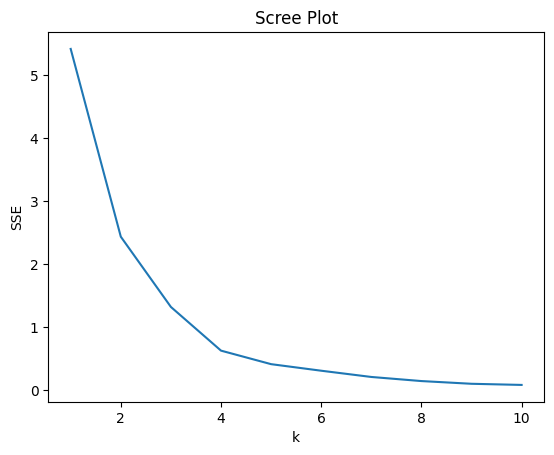

[5.411, 2.435, 1.322, 0.629, 0.415, 0.311, 0.212, 0.147, 0.104, 0.086]


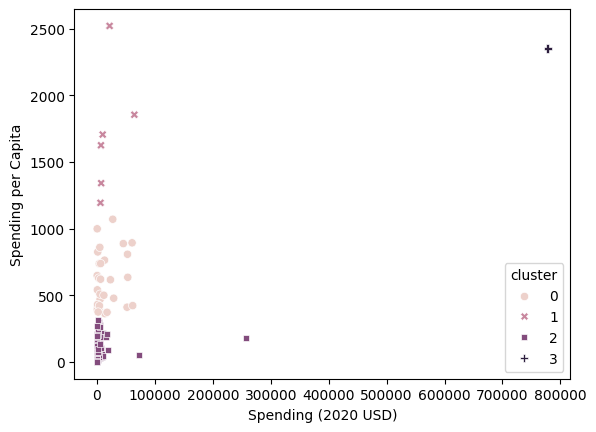

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.20

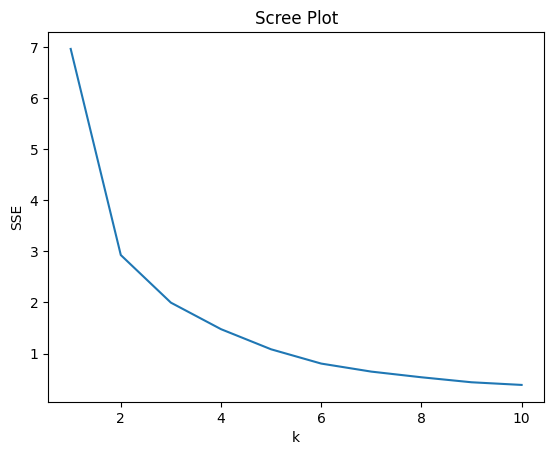

[6.961, 2.927, 1.996, 1.477, 1.083, 0.803, 0.646, 0.535, 0.438, 0.386]


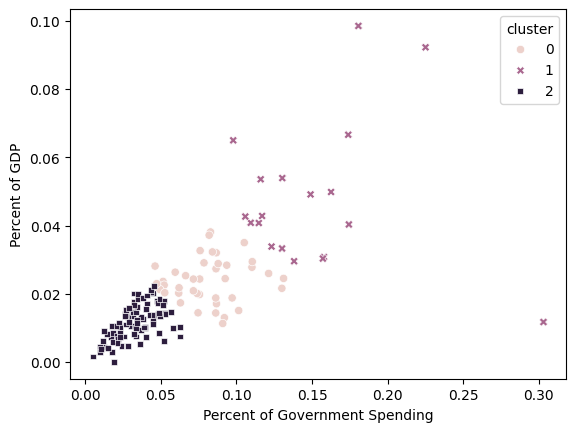

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 40.0  0.081391  0.021601  0.046211   
1                                 19.0  0.150875  0.048785  0.097882   
2                                 89.0  0.033497  0.013242  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.065564  0.082430  0.092176  0.131184           40.0  0.023924   
1        0.116521  0.138143  0.168248  0.303027           19.0  0.047657   
2        0.023300  0.033620  0.043645  0.062685           89.0  0.011698   

                                                                     
              std       min       25%   

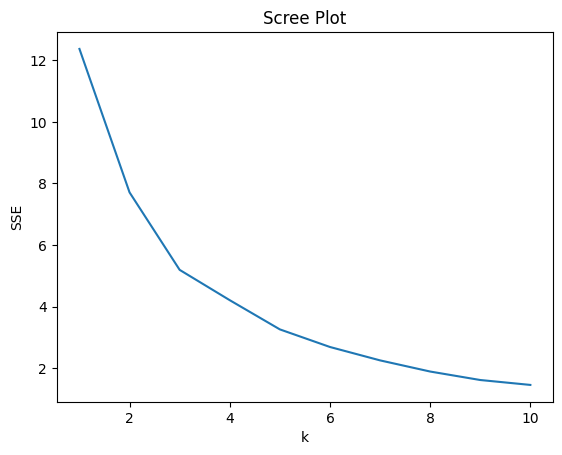

[12.372, 7.71, 5.193, 4.207, 3.258, 2.686, 2.251, 1.889, 1.613, 1.454]


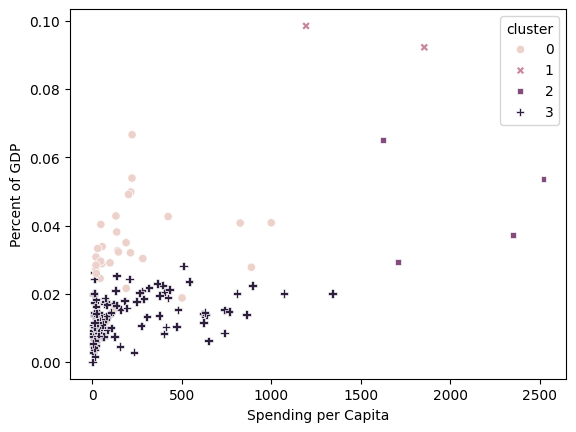

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      31.0    8786.086602   17901.909108   162.373364   
1                       2.0   35327.054356   41339.365456  6095.708713   
2                       4.0  204283.345885  382796.365368  6941.042345   
3                     111.0    7086.472777   26479.379918     8.622460   

                                                                   \
                  25%           50%            75%            max   
cluster                                                             
0          467.787851   1404.787234    7739.166193   72937.064048   
1        20711.381534  35327.054356   49942.727178   64558.400000   
2         9219.189158  15897.570598  210961.727326  778397.200000   
3          130.010211    567.650747    3910.107493  257973.429834  

In [8]:
#Question 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

#1.1 Run Code
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#1.2 Create Scatter Plots
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0] #loop over all five datasets
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

fig, axes = plt.subplots(1, 5, figsize=(20, 4)) #1x5 row of side by side plts
for i, df in enumerate(datasets):
    for group in ['a', 'b', 'c']:
        subset = df[df['group'] == group]
        axes[i].scatter(subset['x1'], subset['x2'], label=group, alpha=0.7)
    axes[i].set_title('Noise = ' + str(noise_levels[i]))
    axes[i].set_xlabel('x1')
    axes[i].set_ylabel('x2')
    axes[i].legend()
plt.tight_layout()
plt.show()

#1.3 Create Scree Plot
ks = np.arange(1, 8) #try k=1-7
plt.figure(figsize=(8, 5))
for df, noise in zip(datasets, noise_levels):
    X = df[['x1', 'x2']] #features only, leave out group label, unsupervided k means
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0) #10 random starts, keep the best
           .fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE, marker='o', label=f'Noise = {noise}') #one curve per npise level
    print(noise, [round(s, 2) for s in SSE])
plt.title('Scree Plot')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

#Question 2
#2.1 Load and Filter Data
df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy() #148 countries, keep 2020 only, drop rows with misisng values

df.sample(20) #looking at other varaibles, no further cleaning required

#2.2 Min-Max Normalize
def scale(features):
    unscaled = df.loc[:, features]
    mins = unscaled.min()
    ranges = unscaled.max() - mins
    return (unscaled - mins) / ranges, mins, ranges #rescale columns 0-1

#2.2 Scree Plot
def scree(X):
    ks = np.arange(1, 11) #try k=1-10
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
           .fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
    plt.show()
    print([round(s, 3) for s in SSE])

#2.2 Scatter Plot
f2 = ['Spending (2020 USD)', 'Spending per Capita'] #features used for clustering
X, mins, ranges = scale(f2)
scree(X) #pick k from the elbow

model = KMeans(n_clusters=4, n_init='auto', random_state=0).fit(X)
df['cluster'] = model.labels_
sns.scatterplot(data=df, x=f2[0], y=f2[1], hue='cluster', style='cluster')
plt.show()
print(df.groupby('cluster')[f2].describe()) #summary stats for each cluster
print(df[df['Country'] == 'United States of America']['cluster'])

#2.3 Repeat
f3 = ['Percent of Government Spending', 'Percent of GDP']
X, mins, ranges = scale(f3)
scree(X)

model = KMeans(n_clusters=3, n_init='auto', random_state=0).fit(X)
df['cluster'] = model.labels_
sns.scatterplot(data=df, x=f3[0], y=f3[1], hue='cluster', style='cluster')
plt.show()
print(df.groupby('cluster')[f3].describe())
print(df[df['Country'] == 'United States of America']['cluster'])

#2.4 Comparison
f4 = ['Spending (2020 USD)', 'Spending per Capita',
      'Percent of Government Spending', 'Percent of GDP'] #all four variables together
X, mins, ranges = scale(f4)
scree(X)

model = KMeans(n_clusters=4, n_init='auto', random_state=0).fit(X)
df['cluster'] = model.labels_
sns.scatterplot(data=df, x=f4[1], y=f4[3], hue='cluster', style='cluster')
plt.show()
print(df.groupby('cluster')[f4].describe())
print(df[df['Country'] == 'United States of America']['cluster'])




**Question 1**

1.2 - As the noise goes up from 0.125 to 2.0, the clusters become less visauly distinct and at 2.0 they eventually merge into one blob. The cluster centers remain the same at every noise level, its only the spread around them that changes.

1.3 - As the noise increases, the elbow in the scree plot becomes weaker making it harder to definitively select a k value.

1.4 - In the simulation with three groups and relatively low noise, SSE drops sharply from k=1 to k=3, as each cluster separates real groups, and barely changes after =3, as extra clusters just split groups that are already compact. The elbow at k=3 therefore reveals the true number of clusters. When noise is high, the groups overlap and the elbow disappears.

**Question 2**

2.1 - No further cleaning of the variables is required.

2.2 - The scree plot bends at about k = 4, which gives four clusters of 111, 30, 6 and 1 countries. The United States is the cluster of 1, with spending of about 778,397 compared with cluster averages of about 4,859 to 19,443. The other clusters are ordered mainly by spending per capita, from about 80 in the large 111-country cluster up to about 1,707 in the 6-country one.

2.3 The United States is in a middle cluster of 40 countries, averaging about 8.1% of government spending and 2.4% of GDP. It is no longer isolated, because these measures don’t depend on how large a country is. The other clusters are a low group of 89 countries (about 3.3% and 1.2%) and a high group of 19 (about 15.1% and 4.8%).

2.4 The United States is in a cluster of 4 countries with very high average spending (about 204,283) and per-capita spending (about 2,051), plus about 10.2% of government spending and 4.6% of GDP. The other clusters are a large low group of 111 countries, a middle group of 31, and a small group of 2 with the highest budget shares (about 20.3% and 9.5%). The United States is grouped with others here, because the percentage features pull it toward other heavy spenders.

2.5 - K-means finds groups of similar countries, and the groups change depending on which measures you use. Its limits are that one extreme country, like the United States in part 2, can end up alone in a cluster, and that the clusters are very uneven in size (111 of 148 countries are in the low cluster in parts 2 and 4). Choosing k is also subjective, since the elbows weren’t sharp.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]